In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

In [3]:
data = pd.read_csv('College_Data.csv', index_col=0)
data.info()

<class 'pandas.DataFrame'>
Index: 777 entries, Abilene Christian University to York College of Pennsylvania
Data columns (total 18 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Private      777 non-null    str    
 1   Apps         777 non-null    int64  
 2   Accept       777 non-null    int64  
 3   Enroll       777 non-null    int64  
 4   Top10perc    777 non-null    int64  
 5   Top25perc    777 non-null    int64  
 6   F.Undergrad  777 non-null    int64  
 7   P.Undergrad  777 non-null    int64  
 8   Outstate     777 non-null    int64  
 9   Room.Board   777 non-null    int64  
 10  Books        777 non-null    int64  
 11  Personal     777 non-null    int64  
 12  PhD          777 non-null    int64  
 13  Terminal     777 non-null    int64  
 14  S.F.Ratio    777 non-null    float64
 15  perc.alumni  777 non-null    int64  
 16  Expend       777 non-null    int64  
 17  Grad.Rate    777 non-null    int64  
dtypes: float64(1),

In [4]:

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

s_data = scaler.fit_transform(data.drop(columns = ['Private']))

In [5]:
pca_data = pca.fit_transform(s_data)

In [6]:
pca_data

array([[-1.5928554 ,  0.76733351],
       [-2.1924018 , -0.57882998],
       [-1.43096371, -1.09281889],
       ...,
       [-0.7325606 , -0.07723524],
       [ 7.91932735, -2.06832886],
       [-0.46950807,  0.36666094]], shape=(777, 2))

In [7]:
pca_frame = pd.DataFrame(
    data = pca_data, 
    columns = ['PC1', 'PC2'],
    index = data.index
)
pca_frame.head()

,PC1,PC2
Abilene Christian University,-1.592855,0.767334
Adelphi University,-2.192402,-0.578830
Adrian College,-1.430964,-1.092819
Agnes Scott College,2.855557,-2.630612
Alaska Pacific University,-2.212008,0.021631


<Axes: xlabel='Room.Board', ylabel='Grad.Rate'>

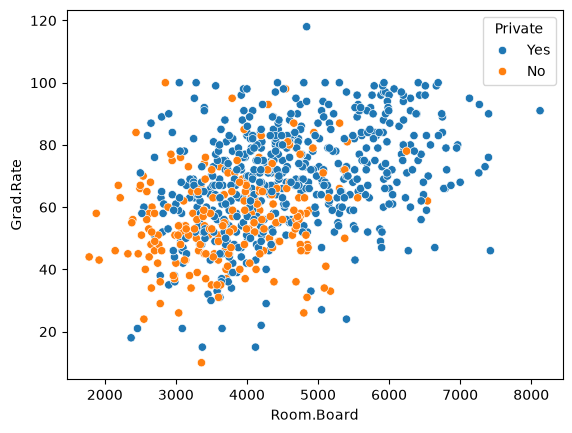

In [8]:
sns.scatterplot(x = 'Room.Board', y = 'Grad.Rate', data = data, hue = 'Private')

In [9]:
pca.components_


array([[ 0.2487656 ,  0.2076015 ,  0.17630359,  0.35427395,  0.34400128,
         0.15464096,  0.0264425 ,  0.29473642,  0.24903045,  0.06475752,
        -0.04252854,  0.31831287,  0.31705602, -0.17695789,  0.20508237,
         0.31890875,  0.25231565],
       [ 0.33159823,  0.37211675,  0.40372425, -0.08241182, -0.04477866,
         0.41767377,  0.31508783, -0.24964352, -0.13780888,  0.05634184,
         0.21992922,  0.05831132,  0.04642945,  0.24666528, -0.24659527,
        -0.13168986, -0.16924053]])

In [14]:
pca_comp = pd.DataFrame(
    data = pca.components_, 
    columns = data.drop(columns = ['Private']).columns
)
pca_comp

,Apps,Accept,Enroll,Top10perc,Top25perc,F.Undergrad,P.Undergrad,Outstate,Room.Board,Books,Personal,PhD,Terminal,S.F.Ratio,perc.alumni,Expend,Grad.Rate
0,0.248766,0.207602,0.176304,0.354274,0.344001,0.154641,0.026443,0.294736,0.249030,0.064758,-0.042529,0.318313,0.317056,-0.176958,0.205082,0.318909,0.252316
1,0.331598,0.372117,0.403724,-0.082412,-0.044779,0.417674,0.315088,-0.249644,-0.137809,0.056342,0.219929,0.058311,0.046429,0.246665,-0.246595,-0.131690,-0.169241


<Axes: >

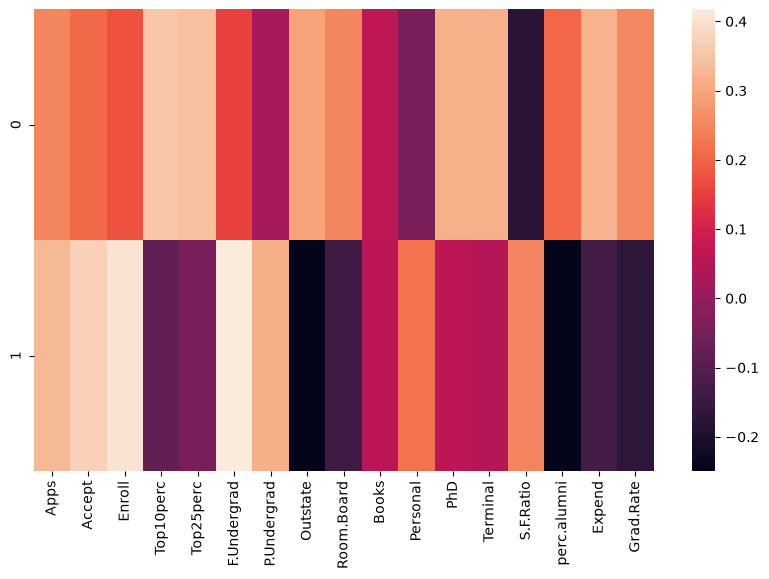

In [17]:
plt.figure(figsize = (10,6))
sns.heatmap(pca_comp)